# PDAN8412/w -POE: Facial Expression Recognition with Convolutional Neural Networks (CNNs)
# Student Name: Boitumelo Mogadingoane
# Student Number : ST10529269
**Dataset:** Nicole, n.d. *FER2013: Facial Expression Recognition Challenge data*. [data set] Kaggle. Available at: <https://www.kaggle.com/datasets/nicolejyt/facialexpressionrecognition> [Accessed 28 October 2026].

**Workflow:** PySpark is used for loading, validating, cleaning and exploratory analysis of FER-2013. The cleaned 48 × 48 greyscale images are then prepared as NumPy arrays, while the CNN is built, trained and evaluated using TensorFlow/Keras. The original `Training`, `PublicTest` and `PrivateTest` partitions are retained for model fitting, validation/model selection and final testing respectively.

> **Code attribution.** Cells marked `# Attribution:` contain code adapted from library documentation or developed with LLM (ChatGPT, OpenAI) assistance and then reviewed, tested and edited. All dataset choices, analytical decisions, model-design decisions, interpretations and conclusions are my own.

## 3a.1 Environment Setup
A local Spark session is created for loading, validating and exploring the FER-2013 dataset. NumPy and pandas will be used where image arrays or small summary tables are required, while Matplotlib will be used for visualisation. A fixed random seed is used to support reproducibility.

In [1]:
# Import the libraries required for the analysis
import random
from pathlib import Path

import numpy as npyFER
import pandas as pndFER
import matplotlib.pyplot as pltFER

# Import PySpark tools for loading, cleaning and analysing FER-2013
from pyspark.sql import SparkSession, functions as F

# Set a fixed random seed so results can be reproduced
SEED = 42
random.seed(SEED)
npyFER.random.seed(SEED)

# Build a portable path to the FER-2013 dataset
DATA_PATH = Path.cwd() / "fer2013.csv"

# Confirm that the dataset exists before Spark attempts to load it
print("Dataset path:", DATA_PATH)
print("File exists:", DATA_PATH.exists())

# Create a local Spark session
spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("FER2013-CNN-Analysis")
    .getOrCreate()
)

# Reduce unnecessary Spark log messages
spark.sparkContext.setLogLevel("ERROR")

Dataset path: C:\Users\tumib\fer2013.csv
File exists: True


## 3a.2 Load FER-2013 and Confirm Its Structure
FER-2013 is loaded into PySpark so that its dimensions, schema and supplied dataset partitions can be verified before preprocessing or exploratory analysis begins.

In [2]:
# Load FER-2013 into Spark, using the first row as column names
# and allowing Spark to infer suitable data types for each column
fer_df = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv(str(DATA_PATH))
)

# Confirm the dataset dimensions, structure and supplied partitions
print("Number of records:", fer_df.count())
print("Number of columns:", len(fer_df.columns))
print("Columns:", fer_df.columns)

fer_df.printSchema()

fer_df.groupBy("Usage").count().orderBy("Usage").show()

Number of records: 35887
Number of columns: 3
Columns: ['emotion', 'pixels', 'Usage']
root
 |-- emotion: integer (nullable = true)
 |-- pixels: string (nullable = true)
 |-- Usage: string (nullable = true)

+-----------+-----+
|      Usage|count|
+-----------+-----+
|PrivateTest| 3589|
| PublicTest| 3589|
|   Training|28709|
+-----------+-----+



## 3a.3 Data Integrity and Pixel Validation

Data integrity checks are performed to identify missing values, invalid class labels, malformed image records and pixel values outside the valid 0-255 grayscale range before further analysis.

In [3]:
# Count missing or blank values in each FER-2013 column
missing_values = fer_df.select([
    F.sum(
        F.when(
            F.col(column).isNull() |
            (F.trim(F.col(column).cast("string")) == ""),
            1
        ).otherwise(0)
    ).alias(column)
    for column in fer_df.columns
])

missing_values.show(vertical=True)

-RECORD 0------
 emotion | 0   
 pixels  | 0   
 Usage   | 0   



In [4]:
# Confirm that emotion labels are restricted to the expected classes 0 to 6
emotion_labels = (
    fer_df
    .select("emotion")
    .distinct()
    .orderBy("emotion")
)

emotion_labels.show()

# Confirm the supplied dataset partition names
usage_labels = (
    fer_df
    .select("Usage")
    .distinct()
    .orderBy("Usage")
)

usage_labels.show()

+-------+
|emotion|
+-------+
|      0|
|      1|
|      2|
|      3|
|      4|
|      5|
|      6|
+-------+

+-----------+
|      Usage|
+-----------+
|PrivateTest|
| PublicTest|
|   Training|
+-----------+



## Verify that every image contains exactly 48 × 48 = 2,304 pixels:

In [5]:
# Count the number of pixel values stored for each image
fer_df = fer_df.withColumn(
    "pixel_count",
    F.size(
        F.split(
            F.trim(F.col("pixels")),
            r"\s+"
        )
    )
)

# Identify records that do not contain exactly 2,304 pixels
pixel_count_check = (
    fer_df
    .groupBy("pixel_count")
    .count()
    .orderBy("pixel_count")
)

pixel_count_check.show()

+-----------+-----+
|pixel_count|count|
+-----------+-----+
|       2304|35887|
+-----------+-----+



## Convert the pixel strings temporarily to numerical arrays so that values can be validated 

In [6]:
# Convert the space-separated pixel string into an array of integers
fer_df = fer_df.withColumn(
    "pixel_values",
    F.transform(
        F.split(F.trim(F.col("pixels")), r"\s+"),
        lambda pixel: pixel.cast("int")
    )
)

## Check for malformed or out-of-range pixel values:

In [7]:
# Check for images with incorrect dimensions, non-numeric pixels,
# or grayscale values outside the valid range of 0 to 255
pixel_validation = fer_df.select(
    F.sum(
        F.when(F.col("pixel_count") != 2304, 1).otherwise(0)
    ).alias("incorrect_pixel_count"),

    F.sum(
        F.when(
            F.expr("exists(pixel_values, x -> x IS NULL)"),
            1
        ).otherwise(0)
    ).alias("non_numeric_pixels"),

    F.sum(
        F.when(
            F.expr("exists(pixel_values, x -> x < 0 OR x > 255)"),
            1
        ).otherwise(0)
    ).alias("out_of_range_pixels")
)

pixel_validation.show()

+---------------------+------------------+-------------------+
|incorrect_pixel_count|non_numeric_pixels|out_of_range_pixels|
+---------------------+------------------+-------------------+
|                    0|                 0|                  0|
+---------------------+------------------+-------------------+



## 3a.4 Class Distribution and Imbalance

The distribution of the seven emotion classes is examined to determine whether class imbalance is present and whether it may affect CNN training and evaluation.

In [8]:
# Map the numeric FER-2013 labels to meaningful emotion names
emotion_names = {
    0: "Angry",
    1: "Disgust",
    2: "Fear",
    3: "Happy",
    4: "Sad",
    5: "Surprise",
    6: "Neutral"
}

# Count the number of images in each emotion class
class_distribution = (
    fer_df
    .groupBy("emotion")
    .count()
    .orderBy("emotion")
)

class_distribution.show()        

+-------+-----+
|emotion|count|
+-------+-----+
|      0| 4953|
|      1|  547|
|      2| 5121|
|      3| 8989|
|      4| 6077|
|      5| 4002|
|      6| 6198|
+-------+-----+



## Then calculate percentages

In [9]:
# Calculate the percentage represented by each emotion class
total_images = fer_df.count()

class_distribution = (
    class_distribution
    .withColumn(
        "percentage",
        F.round(
            F.col("count") / total_images * 100,
            2
        )
    )
)

class_distribution.show()

+-------+-----+----------+
|emotion|count|percentage|
+-------+-----+----------+
|      0| 4953|      13.8|
|      1|  547|      1.52|
|      2| 5121|     14.27|
|      3| 8989|     25.05|
|      4| 6077|     16.93|
|      5| 4002|     11.15|
|      6| 6198|     17.27|
+-------+-----+----------+



## And visualise it

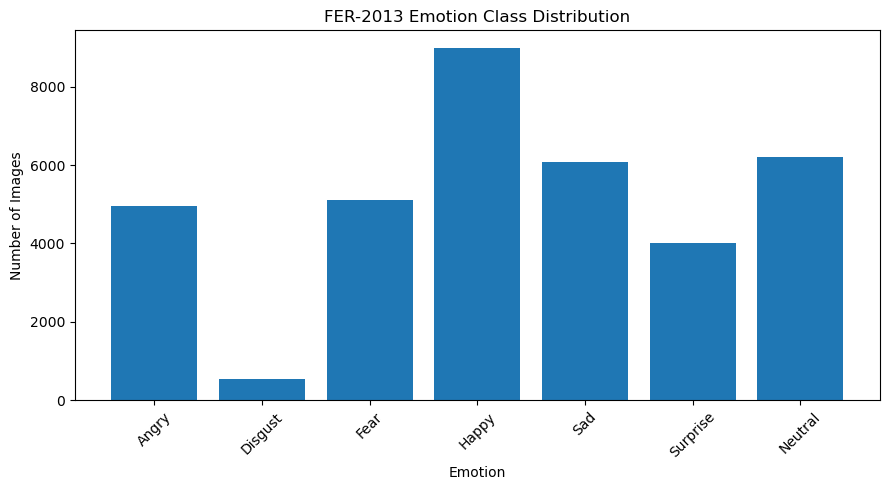

In [10]:
# Convert the small summary table to pandas for visualisation
class_plot = class_distribution.toPandas()

# Replace numeric labels with emotion names
class_plot["emotion_name"] = class_plot["emotion"].map(emotion_names)

# Plot the class distribution
pltFER.figure(figsize=(9, 5))

pltFER.bar(
    class_plot["emotion_name"],
    class_plot["count"]
)

pltFER.title("FER-2013 Emotion Class Distribution")
pltFER.xlabel("Emotion")
pltFER.ylabel("Number of Images")
pltFER.xticks(rotation=45)
pltFER.tight_layout()
pltFER.show()

## 3a.5 Image Quality: Brightness and Pixel Variation

Image-level brightness and pixel variation are examined to identify blank, near-uniform or potentially low-information images. Images with little variation between pixels may contain insufficient facial detail for useful CNN training.

In [11]:
# Calculate the average brightness of each image
fer_df = fer_df.withColumn(
    "mean_brightness",
    F.expr("""
        aggregate(
            pixel_values,
            cast(0 as double),
            (total, pixel) -> total + pixel
        ) / size(pixel_values)
    """)
)

# Calculate the mean of the squared pixel values
fer_df = fer_df.withColumn(
    "mean_squared_pixel",
    F.expr("""
        aggregate(
            pixel_values,
            cast(0 as double),
            (total, pixel) -> total + (pixel * pixel)
        ) / size(pixel_values)
    """)
)

# Calculate pixel variance and standard deviation for each image
fer_df = (
    fer_df
    .withColumn(
        "pixel_variance",
        F.greatest(
            F.col("mean_squared_pixel") -
            F.pow(F.col("mean_brightness"), 2),
            F.lit(0.0)
        )
    )
    .withColumn(
        "pixel_std",
        F.sqrt("pixel_variance")
    )
)

In [12]:
# Summarise image brightness and pixel variation
image_quality_summary = fer_df.select(
    F.round(F.min("mean_brightness"), 2).alias("minimum_brightness"),
    F.round(
        F.expr("percentile_approx(mean_brightness, 0.5)"), 2
    ).alias("median_brightness"),
    F.round(F.max("mean_brightness"), 2).alias("maximum_brightness"),

    F.round(F.min("pixel_std"), 2).alias("minimum_pixel_std"),
    F.round(
        F.expr("percentile_approx(pixel_std, 0.5)"), 2
    ).alias("median_pixel_std"),
    F.round(F.max("pixel_std"), 2).alias("maximum_pixel_std")
)

image_quality_summary.show()

+------------------+-----------------+------------------+-----------------+----------------+-----------------+
|minimum_brightness|median_brightness|maximum_brightness|minimum_pixel_std|median_pixel_std|maximum_pixel_std|
+------------------+-----------------+------------------+-----------------+----------------+-----------------+
|               0.0|           129.54|            248.09|              0.0|           53.63|           114.15|
+------------------+-----------------+------------------+-----------------+----------------+-----------------+



## Check for completely uniform images
An image with a pixel standard deviation of 0 contains no variation at all.

In [13]:
# Count completely uniform images with no pixel variation
uniform_images = (
    fer_df
    .filter(F.col("pixel_std") == 0)
    .count()
)

print("Completely uniform images:", uniform_images)

Completely uniform images: 12


## Low-Variation Image Screening

 Completely uniform images are counted, and the lowest 1% of pixel variation is flagged for closer inspection. These images are screened for possible low-information content before any removal decision is made.

In [14]:
# Calculate the 1st percentile of image pixel variation
low_variation_threshold = fer_df.approxQuantile(
    "pixel_std",
    [0.01],
    0.001
)[0]

print(
    "1st percentile pixel standard deviation:",
    round(low_variation_threshold, 2)
)

# Count images falling within this low-variation group
low_variation_count = (
    fer_df
    .filter(F.col("pixel_std") <= low_variation_threshold)
    .count()
)

print("Low-variation images for inspection:", low_variation_count)

1st percentile pixel standard deviation: 24.81
Low-variation images for inspection: 351


## Image-Quality Distributions

 Brightness and pixel-variation distributions are visualised to assess the overall quality and variability of FER-2013 images.

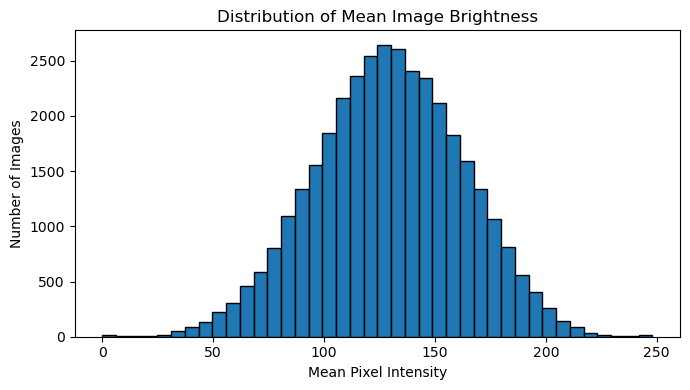

In [15]:
# Convert only the two image-quality measures to pandas for plotting
quality_plot = (
    fer_df
    .select(
        "mean_brightness",
        "pixel_std"
    )
    .toPandas()
)

# Plot the distribution of average image brightness
pltFER.figure(figsize=(7, 4))
pltFER.hist(
    quality_plot["mean_brightness"],
    bins=40,
    edgecolor="black"
)

pltFER.title("Distribution of Mean Image Brightness")
pltFER.xlabel("Mean Pixel Intensity")
pltFER.ylabel("Number of Images")
pltFER.tight_layout()
pltFER.show()

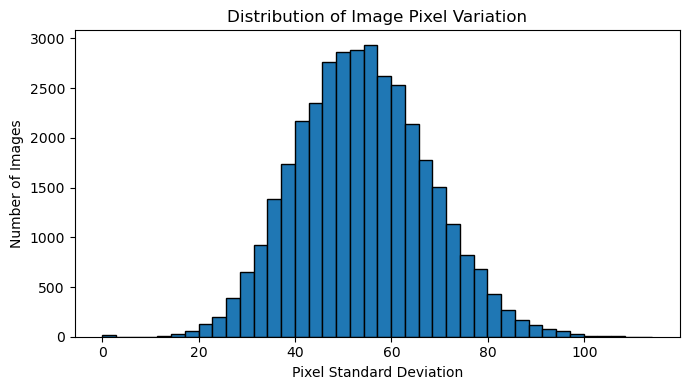

In [16]:
# Plot the distribution of pixel variation
pltFER.figure(figsize=(7, 4))
pltFER.hist(
    quality_plot["pixel_std"],
    bins=40,
    edgecolor="black"
)

pltFER.title("Distribution of Image Pixel Variation")
pltFER.xlabel("Pixel Standard Deviation")
pltFER.ylabel("Number of Images")
pltFER.tight_layout()
pltFER.show()

### 3a.6 Representative Image Visualisation
Representative images from each emotion class are displayed to assess facial detail, image quality and visible similarities between expressions.

In [17]:
# Map numeric emotion labels to meaningful class names
emotion_names = {
    0: "Angry",
    1: "Disgust",
    2: "Fear",
    3: "Happy",
    4: "Sad",
    5: "Surprise",
    6: "Neutral"
}

In [18]:
# Select one reproducible example from each emotion class
from pyspark.sql.window import Window

sample_window = (
    Window
    .partitionBy("emotion")
    .orderBy(F.rand(SEED))
)

sample_images = (
    fer_df
    .withColumn(
        "sample_number",
        F.row_number().over(sample_window)
    )
    .filter(F.col("sample_number") == 1)
    .select("emotion", "pixel_values")
    .orderBy("emotion")
    .collect()
)

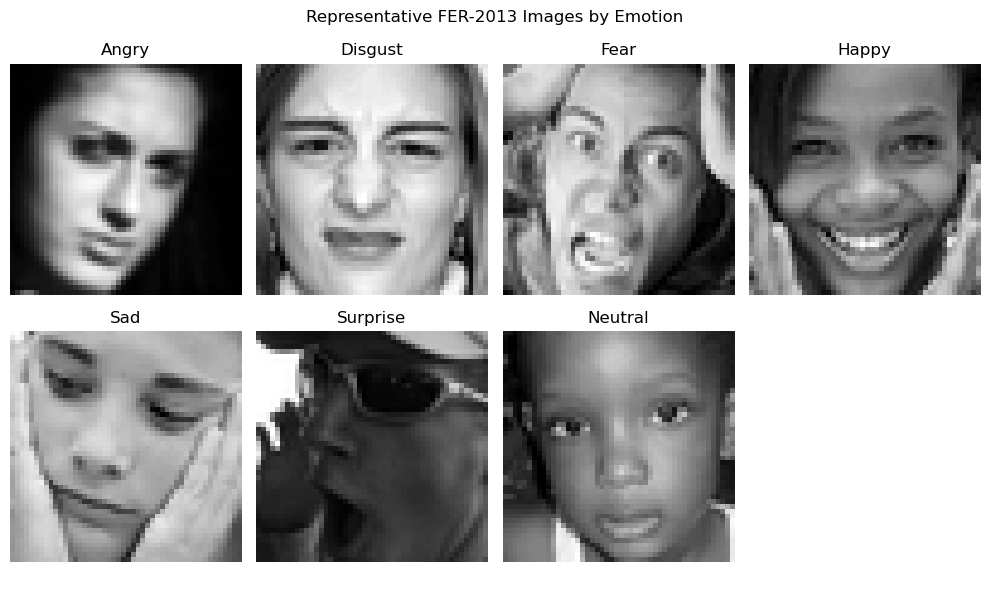

In [19]:
# Display one representative 48 × 48 image for each emotion
fig, axes = pltFER.subplots(2, 4, figsize=(10, 6))

axes = axes.flatten()

for index, row in enumerate(sample_images):

    image = npyFER.array(
        row["pixel_values"]
    ).reshape(48, 48)

    axes[index].imshow(
        image,
        cmap="gray"
    )

    axes[index].set_title(
        emotion_names[row["emotion"]]
    )

    axes[index].axis("off")

# Hide the unused eighth subplot
for index in range(len(sample_images), len(axes)):
    axes[index].axis("off")

pltFER.suptitle(
    "Representative FER-2013 Images by Emotion"
)

pltFER.tight_layout()
pltFER.show()

### 3a.7 Duplicate and Cross-Partition Leakage Check

 Exact duplicate images are checked within and across the supplied dataset partitions. Images duplicated between training and evaluation partitions could cause data leakage and artificially inflate model performance.

In [20]:
# Create a compact fingerprint for each image from its pixel string
# Identical pixel strings will produce the same image hash
fer_df = fer_df.withColumn(
    "image_hash",
    F.sha2(F.col("pixels"), 256)
)

In [21]:
# Group identical images and record how many times and
# in how many dataset partitions each image occurs
duplicate_images = (
    fer_df
    .groupBy("image_hash")
    .agg(
        F.count("*").alias("image_count"),
        F.countDistinct("Usage").alias("partition_count"),
        F.countDistinct("emotion").alias("emotion_count"),
        F.collect_set("Usage").alias("partitions")
    )
    .filter(F.col("image_count") > 1)
)

# Count duplicate image groups
duplicate_groups = duplicate_images.count()

# Count duplicated groups appearing in more than one partition
cross_partition_duplicates = (
    duplicate_images
    .filter(F.col("partition_count") > 1)
    .count()
)

# Count duplicate groups containing conflicting emotion labels
conflicting_labels = (
    duplicate_images
    .filter(F.col("emotion_count") > 1)
    .count()
)

print("Duplicate image groups:", duplicate_groups)
print("Cross-partition duplicate groups:", cross_partition_duplicates)
print("Duplicate groups with conflicting labels:", conflicting_labels)

Duplicate image groups: 1516
Cross-partition duplicate groups: 557
Duplicate groups with conflicting labels: 57


In [22]:
# Group identical images and record how many times and
# in how many dataset partitions each image occurs
duplicate_images = (
    fer_df
    .groupBy("image_hash")
    .agg(
        F.count("*").alias("image_count"),
        F.countDistinct("Usage").alias("partition_count"),
        F.countDistinct("emotion").alias("emotion_count"),
        F.collect_set("Usage").alias("partitions")
    )
    .filter(F.col("image_count") > 1)
)

# Count duplicate image groups
duplicate_groups = duplicate_images.count()

# Count duplicated groups appearing in more than one partition
cross_partition_duplicates = (
    duplicate_images
    .filter(F.col("partition_count") > 1)
    .count()
)

# Count duplicate groups containing conflicting emotion labels
conflicting_labels = (
    duplicate_images
    .filter(F.col("emotion_count") > 1)
    .count()
)

print("Duplicate image groups:", duplicate_groups)
print("Cross-partition duplicate groups:", cross_partition_duplicates)
print("Duplicate groups with conflicting labels:", conflicting_labels)

Duplicate image groups: 1516
Cross-partition duplicate groups: 557
Duplicate groups with conflicting labels: 57


In [23]:
# Display examples of duplicate images found across partitions
duplicate_images.filter(
    F.col("partition_count") > 1
).select(
    "image_count",
    "partition_count",
    "emotion_count",
    "partitions"
).show(10, truncate=False)

+-----------+---------------+-------------+-----------------------------------+
|image_count|partition_count|emotion_count|partitions                         |
+-----------+---------------+-------------+-----------------------------------+
|2          |2              |1            |[Training, PrivateTest]            |
|5          |3              |1            |[Training, PublicTest, PrivateTest]|
|4          |2              |1            |[Training, PrivateTest]            |
|2          |2              |1            |[Training, PublicTest]             |
|2          |2              |1            |[Training, PrivateTest]            |
|2          |2              |1            |[Training, PublicTest]             |
|2          |2              |1            |[Training, PrivateTest]            |
|5          |3              |1            |[Training, PublicTest, PrivateTest]|
|7          |2              |1            |[Training, PrivateTest]            |
|2          |2              |1          

In [24]:
# Count the total number of records contained in duplicate groups
duplicate_records = (
    duplicate_images
    .agg(
        F.sum("image_count").alias("duplicate_records"),
        F.sum(F.col("image_count") - 1).alias("extra_duplicate_records")
    )
)

duplicate_records.show()

+-----------------+-----------------------+
|duplicate_records|extra_duplicate_records|
+-----------------+-----------------------+
|             3369|                   1853|
+-----------------+-----------------------+



### 3a.8 Duplicate Resolution and Final Clean EDA Dataset

 Duplicate and conflicting-label images are resolved before modelling. Conflicting-label images are removed, while exact duplicates are retained only once using the priority PrivateTest --> PublicTest --> Training to prevent evaluation images from also appearing in model-development data.

In [25]:
#Removing all images whose identical pixels have conflicting emotion labels
# Identify image hashes that have been assigned more than one emotion label
conflicting_hashes = (
    fer_df
    .groupBy("image_hash")
    .agg(
        F.countDistinct("emotion").alias("emotion_count")
    )
    .filter(F.col("emotion_count") > 1)
    .select("image_hash")
)

# Count how many records belong to conflicting-label groups
conflicting_records = (
    fer_df
    .join(conflicting_hashes, on="image_hash", how="inner")
    .count()
)

print("Records in conflicting-label groups:", conflicting_records)

# Remove all conflicting-label records
fer_no_conflicts = (
    fer_df
    .join(conflicting_hashes, on="image_hash", how="left_anti")
)

Records in conflicting-label groups: 160


In [26]:
# Resolving remaining duplicates
# Assigning priority so that evaluation records are protected first
# PrivateTest is retained before PublicTest, and PublicTest before Training
fer_no_conflicts = fer_no_conflicts.withColumn(
    "partition_priority",
    F.when(F.col("Usage") == "PrivateTest", 1)
     .when(F.col("Usage") == "PublicTest", 2)
     .otherwise(3)
)

In [27]:
# Keeping only one copy of each identical image
from pyspark.sql.window import Window

duplicate_window = (
    Window
    .partitionBy("image_hash")
    .orderBy(
        "partition_priority",
        "emotion"
    )
)

fer_clean_df = (
    fer_no_conflicts
    .withColumn(
        "duplicate_rank",
        F.row_number().over(duplicate_window)
    )
    .filter(F.col("duplicate_rank") == 1)
    .drop(
        "duplicate_rank",
        "partition_priority"
    )
)

In [28]:
#Then quantify exactly what changed
# Compare dataset size before and after duplicate resolution
original_count = fer_df.count()
clean_count = fer_clean_df.count()

print("Original records:", original_count)
print("Clean records:", clean_count)
print("Records removed:", original_count - clean_count)

Original records: 35887
Clean records: 33977
Records removed: 1910


In [29]:
#checking the new partition sizes
# Confirm the number of records remaining in each partition
clean_partition_summary = (
    fer_clean_df
    .groupBy("Usage")
    .count()
    .orderBy("Usage")
)

clean_partition_summary.show()

+-----------+-----+
|      Usage|count|
+-----------+-----+
|PrivateTest| 3557|
| PublicTest| 3508|
|   Training|26912|
+-----------+-----+



In [30]:
#Finally, verify that there are no remaining exact duplicates
# Confirm that each image hash now occurs only once
remaining_duplicate_groups = (
    fer_clean_df
    .groupBy("image_hash")
    .count()
    .filter(F.col("count") > 1)
    .count()
)

print("Remaining duplicate image groups:", remaining_duplicate_groups)

Remaining duplicate image groups: 0


### 3a.9 Average Face by Emotion

 Average images are calculated for each emotion class to reveal the facial patterns that remain consistent across many observations. Differences and similarities between the average faces provide an indication of which expressions may be easier or harder for the CNN to distinguish.

In [31]:
# Calculate the average face for each emotion class
# Images are processed one class at a time to avoid loading the full dataset into memory
average_faces = {}

for emotion in range(7):

    # Retrieve the cleaned pixel strings for one emotion class
    emotion_rows = (
        fer_clean_df
        .filter(F.col("emotion") == emotion)
        .select("pixels")
        .collect()
    )

    # Convert each pixel string to a numerical 2,304-value array
    emotion_pixels = npyFER.array([
        npyFER.fromstring(
            row["pixels"],
            dtype=npyFER.float32,
            sep=" "
        )
        for row in emotion_rows
    ])

    # Calculate the mean value of each pixel position
    average_faces[emotion] = emotion_pixels.mean(axis=0)

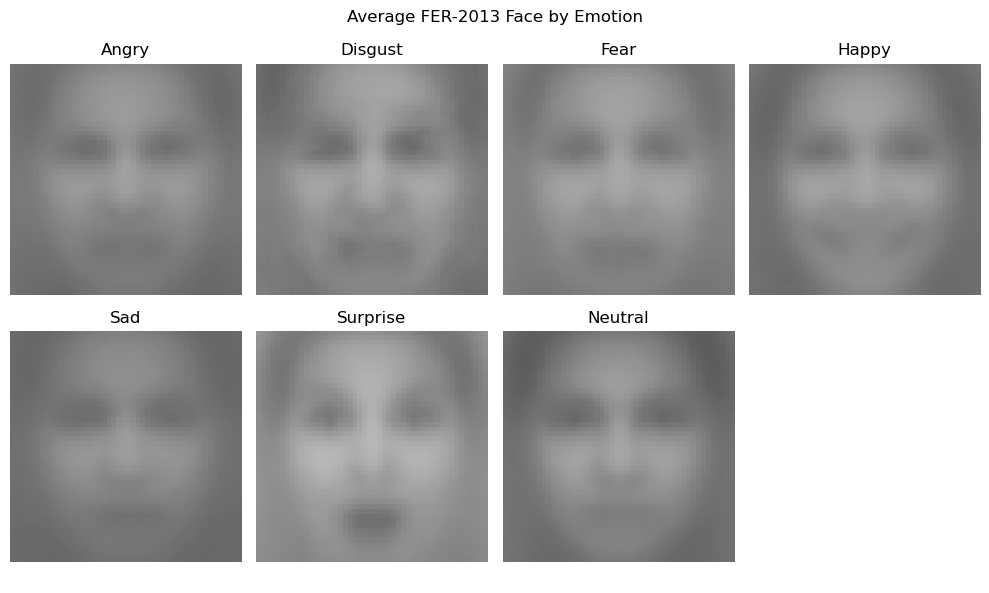

In [32]:
# Display the average face for each emotion class
fig, axes = pltFER.subplots(2, 4, figsize=(10, 6))

axes = axes.flatten()

for emotion in range(7):

    average_image = average_faces[emotion].reshape(48, 48)

    axes[emotion].imshow(
        average_image,
        cmap="gray",
        vmin=0,
        vmax=255
    )

    axes[emotion].set_title(
        emotion_names[emotion]
    )

    axes[emotion].axis("off")

# Hide the unused eighth subplot
axes[7].axis("off")

pltFER.suptitle("Average FER-2013 Face by Emotion")
pltFER.tight_layout()
pltFER.show()

### 3b. Feature Selection and Preprocessing

 A CNN learns relevant image features automatically through its convolutional filters, so no manual feature-selection method is required. The complete 48 × 48 greyscale image is retained as a single input channel. The cleaned dataset is separated using the original FER-2013 partitions, reshaped to `(48, 48, 1)` and normalised from pixel values of 0–255 to 0–1 before training.

In [33]:
# Retain only the variables required for CNN modelling
cnn_df = fer_clean_df.select(
    "emotion",
    "pixels",
    "Usage"
)

print("CNN modelling records:", cnn_df.count())

CNN modelling records: 33977


Above is feature selection in the CNN context: we are deliberately not using brightness, pixel variation, image hashes or other EDA variables as predictors.

## 3b.2 Create Training, Validation and Test Arrays
#### Create CNN Data Partitions

The original FER-2013 partitions are preserved. `Training` is used for model fitting, `PublicTest` for validation and model selection, and `PrivateTest` for final evaluation.

#### Prepare CNN Data Partitions

 A helper function is created to convert each Spark partition into NumPy arrays, reshape the 2,304 pixel values into `(48, 48, 1)` images, and return the corresponding emotion labels.

 The helper function is then applied to the original `Training`, `PublicTest` and `PrivateTest` partitions to create the training, validation and final test datasets used by the CNN.

In [34]:
# Convert one Spark partition into CNN-ready NumPy arrays
def prepare_partition(dataframe, usage_name):

    # Retrieve the label and pixel string for the selected partition
    rows = (
        dataframe
        .filter(F.col("Usage") == usage_name)
        .select("emotion", "pixels")
        .collect()
    )

    # Convert each space-separated pixel string into a numerical array
    images = npyFER.array([
        npyFER.fromstring(
            row["pixels"],
            dtype=npyFER.float32,
            sep=" "
        )
        for row in rows
    ])

    # Convert emotion labels to integers
    labels = npyFER.array(
        [row["emotion"] for row in rows],
        dtype=npyFER.int64
    )

    # Reshape flat 2,304-pixel arrays to 48 × 48 × 1 images
    images = images.reshape(-1, 48, 48, 1)

    return images, labels

In [35]:
# Prepare the training, validation and final test datasets
X_train, y_train = prepare_partition(cnn_df, "Training")
X_val, y_val = prepare_partition(cnn_df, "PublicTest")
X_test, y_test = prepare_partition(cnn_df, "PrivateTest")

In [36]:
# Confirm that the partitions have the expected CNN input structure
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Training: (26912, 48, 48, 1) (26912,)
Validation: (3508, 48, 48, 1) (3508,)
Test: (3557, 48, 48, 1) (3557,)


## 3b.3 Normalise Pixel Values
#### Pixel Normalisation

 Pixel intensities are scaled from the original 0–255 range to 0–1. Normalisation places the CNN inputs on a consistent numerical scale and supports more stable gradient-based optimisation.

In [37]:
# Normalise grayscale pixel values from 0–255 to 0–1
X_train = X_train / 255.0
X_val = X_val / 255.0
X_test = X_test / 255.0

In [38]:
# Confirm the final input shapes and normalised pixel range
print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_test.shape)

print(
    "Training pixel range:",
    round(float(X_train.min()), 2),
    "to",
    round(float(X_train.max()), 2)
)

Training shape: (26912, 48, 48, 1)
Validation shape: (3508, 48, 48, 1)
Test shape: (3557, 48, 48, 1)
Training pixel range: 0.0 to 1.0


### 3c. Baseline CNN Training

 A baseline CNN is trained on the cleaned and normalised FER-2013 training data. The baseline intentionally excludes class weighting and data augmentation so that its natural strengths and weaknesses can first be measured before any retraining decisions are made.

## 3c.1 Import TensorFlow and Set the Seed

In [39]:
# Import TensorFlow/Keras for CNN development
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Dropout,
    Flatten,
    Dense
)
from tensorflow.keras.callbacks import EarlyStopping

# Set the TensorFlow random seed to support reproducibility
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 3c.2 Define the Baseline CNN Architecture
Three convolutional blocks are used to learn increasingly complex facial features. Max-pooling reduces spatial dimensions, while Dropout is included to reduce overfitting. The final softmax layer produces probabilities for the seven emotion classes.



In [40]:
# Build the baseline CNN architecture
baseline_model = Sequential([
    
    # First convolutional block learns basic facial features
    # such as edges, contours and simple textures
    Conv2D(
        32,
        kernel_size=(3, 3),
        activation="relu",
        padding="same",
        input_shape=(48, 48, 1)
    ),
    MaxPooling2D(pool_size=(2, 2)),
    Dropout(0.25),

    # Second block learns more complex combinations of features
    Conv2D(
        64,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ),
    MaxPooling2D(pool_size=(2, 2)),
    Dropout(0.25),

    # Third block learns higher-level facial patterns
    Conv2D(
        128,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ),
    MaxPooling2D(pool_size=(2, 2)),
    Dropout(0.25),

    # Flatten the learned feature maps for classification
    Flatten(),

    # Dense layer combines the extracted features
    Dense(
        128,
        activation="relu"
    ),
    Dropout(0.50),

    # Seven output neurons correspond to the seven emotion classes
    Dense(
        7,
        activation="softmax"
    )
])

C:\Users\tumib\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [41]:
# Display the CNN architecture and number of trainable parameters
baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 683,527 (2.61 MB)

 Trainable params: 683,527 (2.61 MB)

 Non-trainable params: 0 (0.00 B)

#### 3c.3 Compile the Baseline CNN

 Adam is used with a learning rate of 0.001. Sparse categorical cross-entropy is appropriate because the target is a seven-class problem represented by integer labels from 0 to 6.

In [42]:
# Configure the optimiser with the planned learning rate
baseline_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.001
)

# Compile the CNN for multiclass classification
baseline_model.compile(
    optimizer=baseline_optimizer,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

#### 3c.4 Configure Early Stopping
Early Stopping monitors validation loss and stops training if performance fails to improve for five consecutive epochs. The weights from the best-performing epoch are restored to reduce overfitting.

In [43]:
# Stop training when validation loss no longer improves
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

## 3c.5 Train the Baseline Model
The baseline CNN is trained using the cleaned Training partition and validated after each epoch using PublicTest. A batch size of 64 and a maximum of 50 epochs are used. No class weights or data augmentation are applied at this stage so that the baseline model's natural strengths and weaknesses can first be assessed.

# Train the baseline CNN
baseline_history = baseline_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    batch_size=64,
    epochs=50,
    callbacks=[early_stopping],
    verbose=1
)

In [45]:
#After training, confirm how many epochs actually ran
# Report the number of epochs completed before Early Stopping
epochs_completed = len(
    baseline_history.history["loss"]
)

print("Epochs completed:", epochs_completed)

Epochs completed: 28


In [46]:
#one time setup
#%pip install "protobuf==6.31.1"

In [47]:
import google.protobuf
print("protobuf version:", google.protobuf.__version__)

import tensorflow as tf
print("TensorFlow version:", tf.__version__)

protobuf version: 6.31.1
TensorFlow version: 2.21.0


In [48]:
# Import Keras components required for the CNN
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Dropout,
    Flatten,
    Dense
)
from tensorflow.keras.callbacks import EarlyStopping
# Re-establish the fixed seed after restarting the kernel
# Re-establish the fixed seed after restarting the kernel
SEED = 42

random.seed(SEED)
npyFER.random.seed(SEED)
tf.random.set_seed(SEED)

print("Random seed set to:", SEED)


Random seed set to: 42


In [49]:
#### 3c.2Define the Baseline CNN Architecture

The baseline CNN uses three convolutional blocks to learn increasingly complex facial features. Max-pooling reduces spatial dimensions, while Dropout helps limit overfitting. The final softmax layer produces probabilities for the seven emotion classes.


SyntaxError: invalid syntax (2439628943.py, line 3)

### 3c.6 Training Performance

Training and validation accuracy and loss are compared across epochs to assess convergence and identify possible overfitting. Early Stopping ended training after 28 epochs and restored the model weights from the best validation epoch, epoch 23.

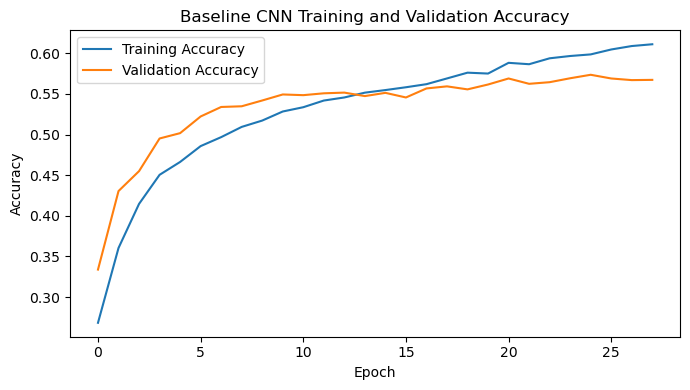

In [50]:
# Plot training and validation accuracy
pltFER.figure(figsize=(7, 4))

pltFER.plot(
    baseline_history.history["accuracy"],
    label="Training Accuracy"
)

pltFER.plot(
    baseline_history.history["val_accuracy"],
    label="Validation Accuracy"
)

pltFER.xlabel("Epoch")
pltFER.ylabel("Accuracy")
pltFER.title("Baseline CNN Training and Validation Accuracy")
pltFER.legend()
pltFER.tight_layout()
pltFER.show()

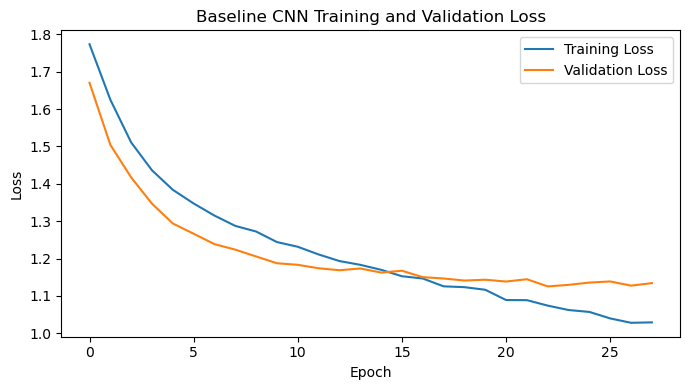

In [51]:
# Plot training and validation loss
pltFER.figure(figsize=(7, 4))

pltFER.plot(
    baseline_history.history["loss"],
    label="Training Loss"
)

pltFER.plot(
    baseline_history.history["val_loss"],
    label="Validation Loss"
)

pltFER.xlabel("Epoch")
pltFER.ylabel("Loss")
pltFER.title("Baseline CNN Training and Validation Loss")
pltFER.legend()
pltFER.tight_layout()
pltFER.show()

In [52]:
# Identify the epoch with the lowest validation loss
best_epoch = npyFER.argmin(
    baseline_history.history["val_loss"]
) + 1

best_val_loss = min(
    baseline_history.history["val_loss"]
)

best_val_accuracy = baseline_history.history["val_accuracy"][
    best_epoch - 1
]

print("Best validation epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 4))
print("Validation accuracy at best epoch:", round(best_val_accuracy, 4))

Best validation epoch: 23
Best validation loss: 1.1254
Validation accuracy at best epoch: 0.5644


### 4a. Baseline Model Evaluation

 The baseline CNN is evaluated on the validation partition using overall accuracy, macro-averaged precision, recall and F1-score, per-class recall and a confusion matrix. These class-sensitive measures are used because the FER-2013 class distribution is imbalanced.

In [53]:
# Import evaluation metrics for multiclass classification
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

In [54]:
# Predict class probabilities for the validation partition
val_probabilities = baseline_model.predict(
    X_val,
    batch_size=64,
    verbose=0
)

# Convert the highest probability into the predicted emotion class
y_val_pred = npyFER.argmax(
    val_probabilities,
    axis=1
)

In [55]:
# Calculate overall and macro-averaged validation metrics
val_accuracy = accuracy_score(
    y_val,
    y_val_pred
)

macro_precision, macro_recall, macro_f1, _ = (
    precision_recall_fscore_support(
        y_val,
        y_val_pred,
        average="macro",
        zero_division=0
    )
)

print("Validation accuracy:", round(val_accuracy, 4))
print("Macro precision:", round(macro_precision, 4))
print("Macro recall:", round(macro_recall, 4))
print("Macro F1-score:", round(macro_f1, 4))

Validation accuracy: 0.5644
Macro precision: 0.6146
Macro recall: 0.4772
Macro F1-score: 0.4842


In [56]:
# Display precision, recall and F1-score for every emotion class
print(
    classification_report(
        y_val,
        y_val_pred,
        target_names=[
            "Angry",
            "Disgust",
            "Fear",
            "Happy",
            "Sad",
            "Surprise",
            "Neutral"
        ],
        digits=3,
        zero_division=0
    )
)

              precision    recall  f1-score   support

       Angry      0.487     0.411     0.446       457
     Disgust      1.000     0.094     0.172        53
        Fear      0.436     0.219     0.292       484
       Happy      0.754     0.821     0.786       888
         Sad      0.416     0.596     0.490       646
    Surprise      0.714     0.693     0.703       381
     Neutral      0.495     0.506     0.500       599

    accuracy                          0.564      3508
   macro avg      0.615     0.477     0.484      3508
weighted avg      0.568     0.564     0.552      3508



In [57]:
# Calculate the baseline validation confusion matrix
baseline_confusion = confusion_matrix(
    y_val,
    y_val_pred
)

print(baseline_confusion)

[[188   0  20  49 104  18  78]
 [ 18   5   6   4  16   0   4]
 [ 44   0 106  37 190  56  51]
 [ 24   0  16 729  53  15  51]
 [ 59   0  32  51 385   9 110]
 [ 12   0  35  30  25 264  15]
 [ 41   0  28  67 152   8 303]]


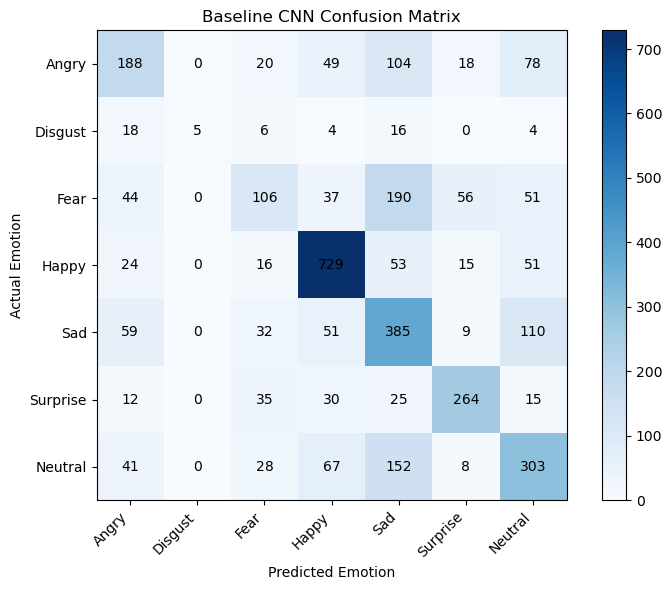

In [58]:
# Display the confusion matrix for the seven emotion classes
emotion_labels = [
    "Angry",
    "Disgust",
    "Fear",
    "Happy",
    "Sad",
    "Surprise",
    "Neutral"
]

fig, ax = pltFER.subplots(figsize=(8, 6))

image = ax.imshow(
    baseline_confusion,
    cmap="Blues"
)

ax.set_xticks(range(7))
ax.set_yticks(range(7))

ax.set_xticklabels(
    emotion_labels,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(emotion_labels)

ax.set_xlabel("Predicted Emotion")
ax.set_ylabel("Actual Emotion")
ax.set_title("Baseline CNN Confusion Matrix")

# Add the count inside each matrix cell
for i in range(7):
    for j in range(7):
        ax.text(
            j,
            i,
            baseline_confusion[i, j],
            ha="center",
            va="center"
        )

pltFER.colorbar(image, ax=ax)
pltFER.tight_layout()
pltFER.show()

### 4b. Retraining with Balanced Class Weights

 The baseline CNN showed very low recall for minority classes, particularly `Disgust`. A second model is therefore trained using balanced class weights calculated from the cleaned training partition. The architecture and other hyperparameters are kept unchanged so that the effect of class weighting can be evaluated fairly.

In [59]:
# Calculate balanced class weights from the training labels only
from sklearn.utils.class_weight import compute_class_weight

classes = npyFER.unique(y_train)

class_weight_values = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(label): float(weight)
    for label, weight in zip(classes, class_weight_values)
}

print("Balanced class weights:")
for label, weight in class_weights.items():
    print(
        emotion_names[label],
        ":",
        round(weight, 3)
    )

Balanced class weights:
Angry : 1.018
Disgust : 10.984
Fear : 1.013
Happy : 0.547
Sad : 0.822
Surprise : 1.563
Neutral : 0.797


In [60]:
# Build a fresh CNN using exactly the same baseline architecture
weighted_model = Sequential([
    tf.keras.Input(shape=(48, 48, 1)),

    Conv2D(32, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    Conv2D(64, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    Conv2D(128, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.50),

    Dense(7, activation="softmax")
])

In [61]:
# Compile the weighted model using the same baseline settings
weighted_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

weighted_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

In [62]:
# Retrain using balanced class weights
weighted_history = weighted_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    batch_size=64,
    epochs=50,
    class_weight=class_weights,
    callbacks=[weighted_early_stopping],
    verbose=1
)

Epoch 1/50
421/421 ━━━━━━━━━━━━━━━━━━━━ 34s 75ms/step - accuracy: 0.1584 - loss: 1.9389 - val_accuracy: 0.2603 - val_loss: 1.9098
Epoch 2/50
421/421 ━━━━━━━━━━━━━━━━━━━━ 32s 76ms/step - accuracy: 0.2222 - loss: 1.8786 - val_accuracy: 0.2443 - val_loss: 1.8263
Epoch 3/50
421/421 ━━━━━━━━━━━━━━━━━━━━ 34s 80ms/step - accuracy: 0.2603 - loss: 1.7985 - val_accuracy: 0.2463 - val_loss: 1.8069
Epoch 4/50
421/421 ━━━━━━━━━━━━━━━━━━━━ 37s 89ms/step - accuracy: 0.3019 - loss: 1.7319 - val_accuracy: 0.3660 - val_loss: 1.6561
Epoch 5/50
421/421 ━━━━━━━━━━━━━━━━━━━━ 34s 81ms/step - accuracy: 0.3355 - loss: 1.6591 - val_accuracy: 0.3783 - val_loss: 1.6148
Epoch 6/50
421/421 ━━━━━━━━━━━━━━━━━━━━ 35s 82ms/step - accuracy: 0.3597 - loss: 1.6034 - val_accuracy: 0.3826 - val_loss: 1.6044
Epoch 7/50
421/421 ━━━━━━━━━━━━━━━━━━━━ 33s 79ms/step - accuracy: 0.3786 - loss: 1.5523 - val_accuracy: 0.3977 - val_loss: 1.5621
Epoch 8/50
421/421 ━━━━━━━━━━━━━━━━━━━━ 33s 79ms/step - accuracy: 0.3934 - loss: 1.5080 - 

#### Evaluate the Class-Weighted CNN

> The class-weighted CNN is evaluated on the same `PublicTest` validation partition as the baseline. Overall and class-sensitive metrics are compared to determine whether weighting improved minority-class recognition.

In [63]:
# Predict emotion probabilities using the class-weighted model
weighted_val_probabilities = weighted_model.predict(
    X_val,
    batch_size=64,
    verbose=0
)

# Select the class with the highest predicted probability
y_val_pred_weighted = npyFER.argmax(
    weighted_val_probabilities,
    axis=1
)

In [64]:
# Calculate validation metrics for the class-weighted model
weighted_accuracy = accuracy_score(
    y_val,
    y_val_pred_weighted
)

weighted_macro_precision, weighted_macro_recall, weighted_macro_f1, _ = (
    precision_recall_fscore_support(
        y_val,
        y_val_pred_weighted,
        average="macro",
        zero_division=0
    )
)

print("Weighted validation accuracy:", round(weighted_accuracy, 4))
print("Weighted macro precision:", round(weighted_macro_precision, 4))
print("Weighted macro recall:", round(weighted_macro_recall, 4))
print("Weighted macro F1-score:", round(weighted_macro_f1, 4))

Weighted validation accuracy: 0.5148
Weighted macro precision: 0.4636
Weighted macro recall: 0.5164
Weighted macro F1-score: 0.4646


In [65]:
# Display per-class performance for the class-weighted model
print(
    classification_report(
        y_val,
        y_val_pred_weighted,
        target_names=[
            "Angry",
            "Disgust",
            "Fear",
            "Happy",
            "Sad",
            "Surprise",
            "Neutral"
        ],
        digits=3,
        zero_division=0
    )
)

              precision    recall  f1-score   support

       Angry      0.426     0.403     0.414       457
     Disgust      0.186     0.623     0.287        53
        Fear      0.419     0.192     0.263       484
       Happy      0.768     0.691     0.728       888
         Sad      0.402     0.481     0.438       646
    Surprise      0.569     0.745     0.645       381
     Neutral      0.474     0.479     0.477       599

    accuracy                          0.515      3508
   macro avg      0.464     0.516     0.465      3508
weighted avg      0.527     0.515     0.511      3508



In [66]:
# Compare baseline and class-weighted validation performance
comparison = pndFER.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1"
    ],
    "Baseline": [
        val_accuracy,
        macro_precision,
        macro_recall,
        macro_f1
    ],
    "Class Weighted": [
        weighted_accuracy,
        weighted_macro_precision,
        weighted_macro_recall,
        weighted_macro_f1
    ]
})

print(comparison.round(4))

            Metric  Baseline  Class Weighted
0         Accuracy    0.5644          0.5148
1  Macro Precision    0.6146          0.4636
2     Macro Recall    0.4772          0.5164
3         Macro F1    0.4842          0.4646


In [67]:
# Define conservative augmentation for 48 × 48 facial images
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.04),
    tf.keras.layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05
    ),
    tf.keras.layers.RandomZoom(0.10)
])

In [68]:
# Build a fresh CNN with training-only augmentation
augmented_model = Sequential([
    tf.keras.Input(shape=(48, 48, 1)),

    data_augmentation,

    Conv2D(32, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    Conv2D(64, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    Conv2D(128, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.50),

    Dense(7, activation="softmax")
])

In [69]:
augmented_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

augmentation_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

In [70]:
augmented_history = augmented_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    batch_size=64,
    epochs=50,
    callbacks=[augmentation_early_stopping],
    verbose=1
)

Epoch 1/50
421/421 ━━━━━━━━━━━━━━━━━━━━ 43s 95ms/step - accuracy: 0.2558 - loss: 1.7954 - val_accuracy: 0.2728 - val_loss: 1.7552
Epoch 2/50
421/421 ━━━━━━━━━━━━━━━━━━━━ 42s 99ms/step - accuracy: 0.2985 - loss: 1.7262 - val_accuracy: 0.3777 - val_loss: 1.6264
Epoch 3/50
421/421 ━━━━━━━━━━━━━━━━━━━━ 42s 100ms/step - accuracy: 0.3347 - loss: 1.6658 - val_accuracy: 0.4176 - val_loss: 1.5522
Epoch 4/50
421/421 ━━━━━━━━━━━━━━━━━━━━ 44s 104ms/step - accuracy: 0.3641 - loss: 1.6174 - val_accuracy: 0.4373 - val_loss: 1.4897
Epoch 5/50
421/421 ━━━━━━━━━━━━━━━━━━━━ 43s 102ms/step - accuracy: 0.3856 - loss: 1.5725 - val_accuracy: 0.4550 - val_loss: 1.4605
Epoch 6/50
421/421 ━━━━━━━━━━━━━━━━━━━━ 42s 101ms/step - accuracy: 0.3972 - loss: 1.5366 - val_accuracy: 0.4698 - val_loss: 1.4128
Epoch 7/50
421/421 ━━━━━━━━━━━━━━━━━━━━ 41s 96ms/step - accuracy: 0.4147 - loss: 1.5132 - val_accuracy: 0.4889 - val_loss: 1.3564
Epoch 8/50
421/421 ━━━━━━━━━━━━━━━━━━━━ 40s 94ms/step - accuracy: 0.4278 - loss: 1.480

### 4c. Retraining with Data Augmentation

> A third CNN was trained using conservative augmentation on the training data only to reduce overfitting and improve generalisation. The architecture and optimisation settings were kept unchanged so that the effect of augmentation could be assessed fairly.

In [71]:
# Predict validation classes using the augmented model
augmented_val_probabilities = augmented_model.predict(
    X_val,
    batch_size=64,
    verbose=0
)

y_val_pred_augmented = npyFER.argmax(
    augmented_val_probabilities,
    axis=1
)

In [72]:
# Calculate validation metrics for the augmented model
augmented_accuracy = accuracy_score(
    y_val,
    y_val_pred_augmented
)

augmented_macro_precision, augmented_macro_recall, augmented_macro_f1, _ = (
    precision_recall_fscore_support(
        y_val,
        y_val_pred_augmented,
        average="macro",
        zero_division=0
    )
)

print("Augmented validation accuracy:", round(augmented_accuracy, 4))
print("Augmented macro precision:", round(augmented_macro_precision, 4))
print("Augmented macro recall:", round(augmented_macro_recall, 4))
print("Augmented macro F1-score:", round(augmented_macro_f1, 4))

Augmented validation accuracy: 0.5567
Augmented macro precision: 0.5982
Augmented macro recall: 0.466
Augmented macro F1-score: 0.4627


In [73]:
# Display per-class results for the augmented model
print(
    classification_report(
        y_val,
        y_val_pred_augmented,
        target_names=[
            "Angry",
            "Disgust",
            "Fear",
            "Happy",
            "Sad",
            "Surprise",
            "Neutral"
        ],
        digits=3,
        zero_division=0
    )
)

              precision    recall  f1-score   support

       Angry      0.494     0.433     0.462       457
     Disgust      1.000     0.038     0.073        53
        Fear      0.384     0.202     0.265       484
       Happy      0.745     0.836     0.788       888
         Sad      0.425     0.467     0.445       646
    Surprise      0.690     0.730     0.709       381
     Neutral      0.449     0.556     0.497       599

    accuracy                          0.557      3508
   macro avg      0.598     0.466     0.463      3508
weighted avg      0.551     0.557     0.541      3508



In [74]:
# Compare all three validation models
model_comparison = pndFER.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1"
    ],
    "Baseline": [
        val_accuracy,
        macro_precision,
        macro_recall,
        macro_f1
    ],
    "Class Weighted": [
        weighted_accuracy,
        weighted_macro_precision,
        weighted_macro_recall,
        weighted_macro_f1
    ],
    "Augmented": [
        augmented_accuracy,
        augmented_macro_precision,
        augmented_macro_recall,
        augmented_macro_f1
    ]
})

print(model_comparison.round(4))

            Metric  Baseline  Class Weighted  Augmented
0         Accuracy    0.5644          0.5148     0.5567
1  Macro Precision    0.6146          0.4636     0.5982
2     Macro Recall    0.4772          0.5164     0.4660
3         Macro F1    0.4842          0.4646     0.4627


### 4d. Final Model Selection

The baseline CNN is selected as the final model because it achieved the highest validation macro-F1 (**48.42%**) while also providing the highest overall accuracy (**56.44%**) and macro precision (**61.46%**). The class-weighted model improved minority-class recall but reduced macro-F1, while augmentation produced no improvement over the baseline.

In [75]:
# Predict probabilities for the untouched final test partition
test_probabilities = baseline_model.predict(
    X_test,
    batch_size=64,
    verbose=0
)

# Convert probabilities to predicted emotion classes
y_test_pred = npyFER.argmax(
    test_probabilities,
    axis=1
)

In [76]:
# Calculate final test-set performance
test_accuracy = accuracy_score(
    y_test,
    y_test_pred
)

test_macro_precision, test_macro_recall, test_macro_f1, _ = (
    precision_recall_fscore_support(
        y_test,
        y_test_pred,
        average="macro",
        zero_division=0
    )
)

print("Final test accuracy:", round(test_accuracy, 4))
print("Final macro precision:", round(test_macro_precision, 4))
print("Final macro recall:", round(test_macro_recall, 4))
print("Final macro F1-score:", round(test_macro_f1, 4))

Final test accuracy: 0.5775
Final macro precision: 0.5725
Final macro recall: 0.4863
Final macro F1-score: 0.4897


In [77]:
# Display final per-class test performance
print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=[
            "Angry",
            "Disgust",
            "Fear",
            "Happy",
            "Sad",
            "Surprise",
            "Neutral"
        ],
        digits=3,
        zero_division=0
    )
)

              precision    recall  f1-score   support

       Angry      0.527     0.426     0.471       484
     Disgust      0.600     0.055     0.100        55
        Fear      0.465     0.271     0.342       521
       Happy      0.752     0.849     0.798       876
         Sad      0.401     0.574     0.472       589
    Surprise      0.725     0.673     0.698       407
     Neutral      0.537     0.557     0.547       625

    accuracy                          0.577      3557
   macro avg      0.572     0.486     0.490      3557
weighted avg      0.578     0.577     0.566      3557



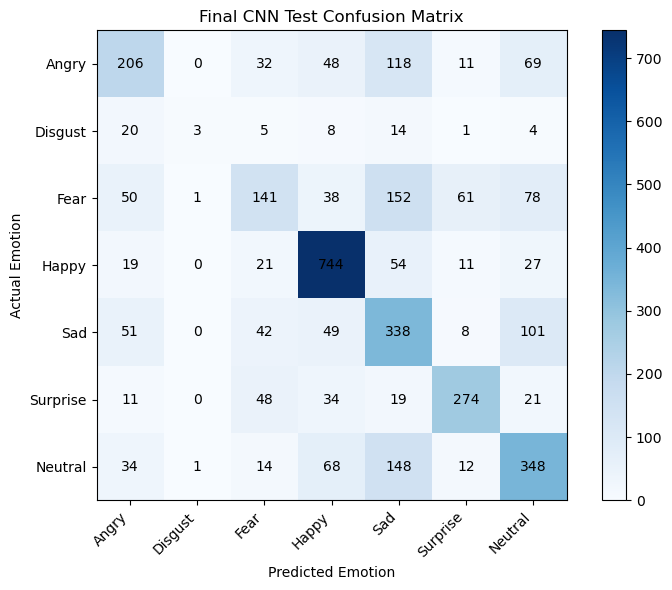

In [78]:
# Calculate the final test confusion matrix
test_confusion = confusion_matrix(
    y_test,
    y_test_pred
)

# Display the final confusion matrix
fig, ax = pltFER.subplots(figsize=(8, 6))

image = ax.imshow(
    test_confusion,
    cmap="Blues"
)

ax.set_xticks(range(7))
ax.set_yticks(range(7))

ax.set_xticklabels(
    emotion_labels,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(emotion_labels)

ax.set_xlabel("Predicted Emotion")
ax.set_ylabel("Actual Emotion")
ax.set_title("Final CNN Test Confusion Matrix")

for i in range(7):
    for j in range(7):
        ax.text(
            j,
            i,
            test_confusion[i, j],
            ha="center",
            va="center"
        )

pltFER.colorbar(image, ax=ax)
pltFER.tight_layout()
pltFER.show()

The confusion matrix shows that the CNN performs best on visually distinctive expressions such as Happy and Surprise. More subtle expressions are harder to separate: Fear is frequently predicted as Sad, while Sad and Neutral are often confused with one another. Disgust remains particularly difficult because of its very small representation in the dataset. These errors are consistent with the class imbalance and visual overlap identified during EDA.